In [1]:
#import and config 
import os
import numpy as np
import pandas as pd
import tensorflow as tf

processed_path = "../dataset/processed"
models_path = "../Models"

retrieval_interactions = pd.read_parquet(
    os.path.join(processed_path, "retrieval_interactions.parquet")
)

faiss_recommendations = pd.read_parquet(
    os.path.join(processed_path, "faiss_recommendations.parquet")
)

ranked_recommendations = pd.read_parquet(
    os.path.join(processed_path, "ranked_recommendations.parquet")
)

print("Retrieval interactions:", retrieval_interactions.shape)
print("FAISS recommendations:", faiss_recommendations.shape)
print("Ranked recommendations:", ranked_recommendations.shape)
print("TensorFlow:", tf.__version__)


Retrieval interactions: (575281, 3)
FAISS recommendations: (60380, 4)
Ranked recommendations: (60380, 4)
TensorFlow: 2.21.0


In [2]:
#train and test split
retrieval_sorted = retrieval_interactions.sort_values(
    ["user_id", "timestamp"]
).copy()

retrieval_sorted["position"] = (
    retrieval_sorted.groupby("user_id").cumcount()
)

retrieval_sorted["user_count"] = (
    retrieval_sorted.groupby("user_id")["user_id"].transform("size")
)

retrieval_sorted["test_count"] = np.where(
    retrieval_sorted["user_count"] >= 2,
    np.maximum(1, np.ceil(retrieval_sorted["user_count"] * 0.2)),
    0
)

retrieval_train = retrieval_sorted[
    retrieval_sorted["position"] <
    retrieval_sorted["user_count"] - retrieval_sorted["test_count"]
].copy()

retrieval_test = retrieval_sorted[
    retrieval_sorted["position"] >=
    retrieval_sorted["user_count"] - retrieval_sorted["test_count"]
].copy()

print("Training interactions:", retrieval_train.shape)
print("Testing interactions:", retrieval_test.shape)
print("Test users:", retrieval_test["user_id"].nunique())

Training interactions: (457819, 6)
Testing interactions: (117462, 6)
Test users: 6037


In [3]:
#ground truth relevant movies
ground_truth = (
    retrieval_test
    .groupby("user_id")["movie_id"]
    .apply(set)
    .to_dict()
)

print("Users with ground-truth items:", len(ground_truth))
print("Total relevant test interactions:", sum(
    len(items) for items in ground_truth.values()
))
print("Example user 1:", list(ground_truth.get("1", set()))[:10])

Users with ground-truth items: 6037
Total relevant test interactions: 117462
Example user 1: ['2355', '1566', '783', '588', '1', '2294', '595', '48', '1907']


In [4]:
#creating evaluation metrics
def evaluate_recommendations(recommendations, ground_truth, k):
    recalls = []
    precisions = []
    ndcgs = []

    recommendations = recommendations.copy()
    recommendations["user_id"] = recommendations["user_id"].astype(str)
    recommendations["movie_id"] = recommendations["movie_id"].astype(str)

    for user_id, relevant_items in ground_truth.items():
        user_recs = (
            recommendations[recommendations["user_id"] == str(user_id)]
            .sort_values("rank")
            ["movie_id"].head(k).tolist()
        )

        if not user_recs:
            continue

        hits = [1 if movie in relevant_items else 0 for movie in user_recs]

        recall = sum(hits) / len(relevant_items)
        precision = sum(hits) / k

        dcg = sum(
            hit / np.log2(position + 2)
            for position, hit in enumerate(hits)
        )

        ideal_hits = min(len(relevant_items), k)

        idcg = sum(
            1 / np.log2(position + 2)
            for position in range(ideal_hits)
        )

        ndcg = dcg / idcg if idcg > 0 else 0

        recalls.append(recall)
        precisions.append(precision)
        ndcgs.append(ndcg)

    return {
        f"Recall@{k}": np.mean(recalls),
        f"Precision@{k}": np.mean(precisions),
        f"NDCG@{k}": np.mean(ndcgs)
    }


print("Evaluation metrics function created successfully.")

Evaluation metrics function created successfully.


In [5]:
#evaluating the faiss recommendations
faiss_metrics = evaluate_recommendations(
    faiss_recommendations,
    ground_truth,
    k=10
)

print("FAISS Retrieval Metrics:")
for metric, value in faiss_metrics.items():
    print(f"{metric}: {value:.4f}")

FAISS Retrieval Metrics:
Recall@10: 0.0565
Precision@10: 0.0612
NDCG@10: 0.0736


In [6]:
#evaluating the final ranking model 
ranking_metrics = evaluate_recommendations(
    ranked_recommendations,
    ground_truth,
    k=10
)

print("Ranking Model Metrics:")
for metric, value in ranking_metrics.items():
    print(f"{metric}: {value:.4f}")

Ranking Model Metrics:
Recall@10: 0.0565
Precision@10: 0.0612
NDCG@10: 0.0765


In [7]:
#creating and saving the evaluation results 
evaluation_results = pd.DataFrame(
    [faiss_metrics, ranking_metrics],
    index=["FAISS Retrieval", "Ranking Model"]
)

evaluation_results.index.name = "Model"

os.makedirs("../Outputs", exist_ok=True)

evaluation_results.to_csv(
    "../Outputs/evaluation_metrics.csv"
)

display(evaluation_results)

print("Evaluation metrics saved successfully.")

,Recall@10,Precision@10,NDCG@10
Model,,,
FAISS Retrieval,0.056502,0.061222,0.073608
Ranking Model,0.056502,0.061222,0.076450


Evaluation metrics saved successfully.


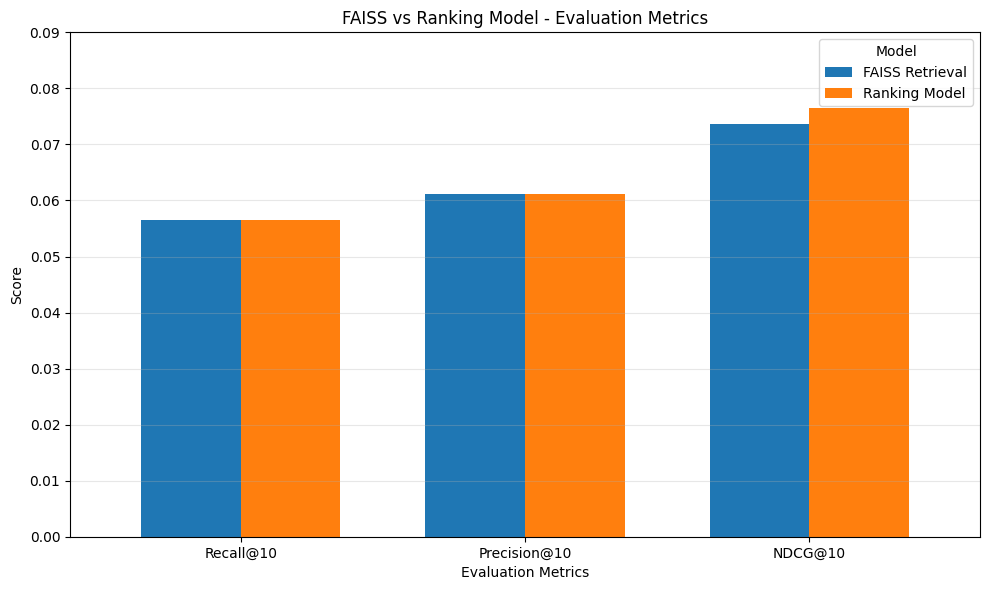

Comparison chart saved successfully.


In [8]:
#visualization 
import matplotlib.pyplot as plt

metrics = ["Recall@10", "Precision@10", "NDCG@10"]

ax = evaluation_results[metrics].T.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.7
)

ax.set_title("FAISS vs Ranking Model - Evaluation Metrics")
ax.set_ylabel("Score")
ax.set_xlabel("Evaluation Metrics")
ax.set_ylim(0, 0.09)
ax.set_xticklabels(metrics, rotation=0)
ax.legend(title="Model")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "../Outputs/evaluation_metrics_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Comparison chart saved successfully.")

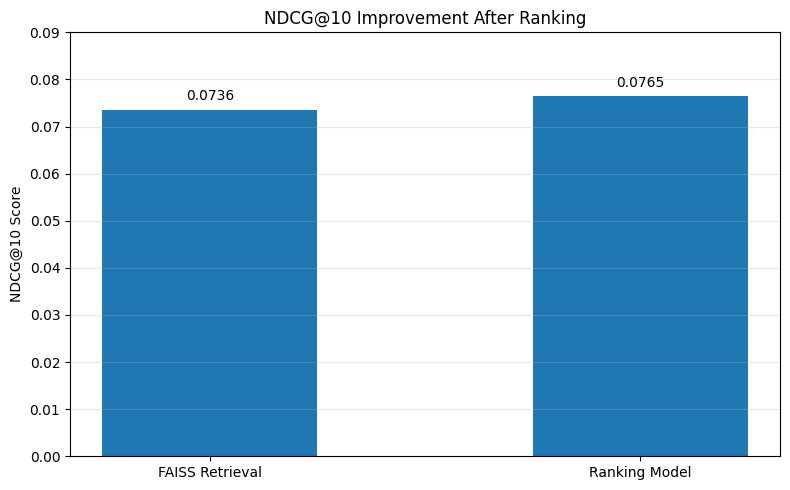

NDCG improvement chart saved successfully.


In [9]:
#Visualizing the  ranking improvement
plt.figure(figsize=(8, 5))

models = ["FAISS Retrieval", "Ranking Model"]
ndcg_scores = [
    faiss_metrics["NDCG@10"],
    ranking_metrics["NDCG@10"]
]

bars = plt.bar(models, ndcg_scores, width=0.5)

plt.title("NDCG@10 Improvement After Ranking")
plt.ylabel("NDCG@10 Score")
plt.ylim(0, 0.09)

for bar, score in zip(bars, ndcg_scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.002,
        f"{score:.4f}",
        ha="center"
    )

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../Outputs/ndcg_improvement.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("NDCG improvement chart saved successfully.")

In [10]:
#saving the detailed evaluation 
def get_user_metrics(recommendations, ground_truth, model_name, k=10):
    rows = []

    recommendations = recommendations.copy()
    recommendations["user_id"] = recommendations["user_id"].astype(str)
    recommendations["movie_id"] = recommendations["movie_id"].astype(str)

    for user_id, relevant_items in ground_truth.items():
        user_recs = (
            recommendations[recommendations["user_id"] == str(user_id)]
            .sort_values("rank")["movie_id"].head(k).tolist()
        )

        hits = [int(movie in relevant_items) for movie in user_recs]

        dcg = sum(
            hit / np.log2(position + 2)
            for position, hit in enumerate(hits)
        )

        ideal_hits = min(len(relevant_items), k)
        idcg = sum(
            1 / np.log2(position + 2)
            for position in range(ideal_hits)
        )

        rows.append({
            "user_id": user_id,
            "model": model_name,
            "relevant_items": len(relevant_items),
            "recommended_items": len(user_recs),
            "hits": sum(hits),
            "recall@10": sum(hits) / len(relevant_items),
            "precision@10": sum(hits) / k,
            "ndcg@10": dcg / idcg if idcg else 0
        })

    return pd.DataFrame(rows)


user_evaluation = pd.concat([
    get_user_metrics(faiss_recommendations, ground_truth, "FAISS Retrieval"),
    get_user_metrics(ranked_recommendations, ground_truth, "Ranking Model")
], ignore_index=True)

user_evaluation.to_csv(
    "../Outputs/per_user_evaluation.csv",
    index=False
)

print("Per-user evaluation shape:", user_evaluation.shape)
print("Unique evaluated users:", user_evaluation["user_id"].nunique())
print("Detailed evaluation evidence saved successfully.")

Per-user evaluation shape: (12074, 8)
Unique evaluated users: 6037
Detailed evaluation evidence saved successfully.
